In [2]:
# 1. Load the dataset in Python environment
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('train_loan.csv')

# Display the first 5 rows
print("First 5 Rows of the Dataset\n")
display(df.head())

# Display basic information about the dataset
print("\nDataset Info\n")
print(df.info())

# Dataset dimensions
print(f"\nDataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")

First 5 Rows of the Dataset



,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Dataset Info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None

Dataset Shape: 614 rows and 13 columns


In [3]:
# 2. Perform different preprocessing steps
# a. Missing value handling

# Check missing values before handling
print("\nMissing Values\n")
print(df.isnull().sum())

# Drop 'Loan_ID' as it is a unique identifier
df = df.drop(columns=['Loan_ID'])

# Handle missing values for categorical columns using Mode
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Handle missing values for numerical columns using Median
numerical_cols = ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Verify missing values after handling
print("\nMissing values after handling:\n", df.isnull().sum())


Missing Values

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Missing values after handling:
 Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


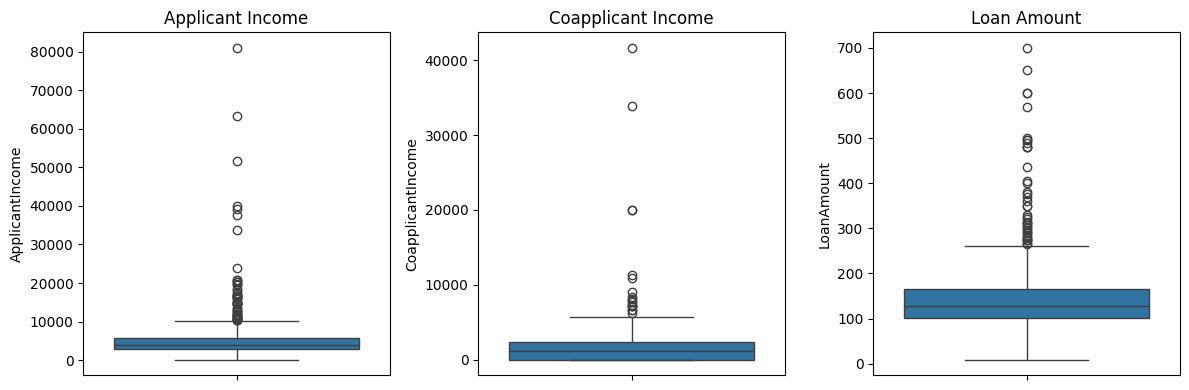

Outliers handled successfully via IQR capping.


In [4]:
# b. Outlier detection

# Visualize outliers using boxplots
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.boxplot(y=df['ApplicantIncome'])
plt.title('Applicant Income')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['CoapplicantIncome'])
plt.title('Coapplicant Income')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['LoanAmount'])
plt.title('Loan Amount')
plt.tight_layout()
plt.show()

# IQR-based outlier capping function for numerical columns
def cap_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data[column] = np.where(data[column] < lower_bound, lower_bound, data[column])
    data[column] = np.where(data[column] > upper_bound, upper_bound, data[column])

# Apply outlier capping
for col in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']:
    cap_outliers(df, col)

print("Outliers handled successfully via IQR capping.")

In [5]:
# c. Encoding

from sklearn.preprocessing import LabelEncoder

# Encode binary and ordinal categorical columns
binary_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

# Handle 'Dependents' (convert string values like '3+' to numerical integer)
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)

# One-Hot Encoding for 'Property_Area'
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True)

# Display encoded dataframe head
print("\nEncoded DataFrame Preview\n")
display(df.head())
print("\nData types after encoding:\n", df.dtypes)


Encoded DataFrame Preview



,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,5849.0,0.0,128.0,360.0,1.0,1,False,True
1,1,1,1,0,0,4583.0,1508.0,128.0,360.0,1.0,0,False,False
2,1,1,0,0,1,3000.0,0.0,66.0,360.0,1.0,1,False,True
3,1,1,0,1,0,2583.0,2358.0,120.0,360.0,1.0,1,False,True
4,1,0,0,0,0,6000.0,0.0,141.0,360.0,1.0,1,False,True



Data types after encoding:
 Gender                       int64
Married                      int64
Dependents                   int64
Education                    int64
Self_Employed                int64
ApplicantIncome            float64
CoapplicantIncome          float64
LoanAmount                 float64
Loan_Amount_Term           float64
Credit_History             float64
Loan_Status                  int64
Property_Area_Semiurban       bool
Property_Area_Urban           bool
dtype: object


In [6]:
# d. Scaling

from sklearn.preprocessing import StandardScaler

# continuous numerical columns to scale
scale_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

# Display scaled dataframe head and summary statistics
print("\nScaled DataFrame Preview\n")
display(df.head())
print("\nSummary Statistics After Scaling\n")
display(df.describe())


Scaled DataFrame Preview



,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,0.497164,-0.874587,-0.168041,0.273231,1.0,1,False,True
1,1,1,1,0,0,-0.013767,0.054395,-0.168041,0.273231,1.0,0,False,False
2,1,1,0,0,1,-0.652632,-0.874587,-1.280462,0.273231,1.0,1,False,True
3,1,1,0,1,0,-0.820924,0.578025,-0.311579,0.273231,1.0,1,False,True
4,1,0,0,0,0,0.558104,-0.874587,0.065209,0.273231,1.0,1,False,True



Summary Statistics After Scaling



,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
count,614.000000,614.000000,614.000000,614.000000,614.000000,6.140000e+02,6.140000e+02,6.140000e+02,6.140000e+02,614.000000,614.000000
mean,0.817590,0.653094,0.744300,0.218241,0.133550,1.764784e-16,9.257886e-17,1.012581e-16,5.930833e-17,0.855049,0.687296
std,0.386497,0.476373,1.009623,0.413389,0.340446,1.000815e+00,1.000815e+00,1.000815e+00,1.000815e+00,0.352339,0.463973
min,0.000000,0.000000,0.000000,0.000000,0.000000,-1.802831e+00,-8.745873e-01,-2.303171e+00,-5.132498e+00,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,0.000000,-7.020702e-01,-8.745873e-01,-6.659388e-01,2.732313e-01,1.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,0.000000,-3.247241e-01,-1.424288e-01,-1.680408e-01,2.732313e-01,1.000000,1.000000
75%,1.000000,1.000000,1.000000,0.000000,0.000000,4.753707e-01,5.406008e-01,4.913377e-01,2.732313e-01,1.000000,1.000000
max,1.000000,1.000000,3.000000,1.000000,1.000000,2.241532e+00,2.663383e+00,2.227252e+00,2.137276e+00,1.000000,1.000000
